# Formativa 1 de MCDI501
## Exploración e inferencia de lluvias en Australia

**Universidad Andrés Bello · Magíster en Ciencia de Datos e Inteligencia Artificial**  
**Grupo 7 · Responsable identificado: Benjamín Araya · Evaluación formativa, ponderación 0 %**

Estudiamos la estructura y calidad de `weatherAUS.csv` y las relaciones meteorológicas
asociadas con `RainTomorrow`. La pregunta general es si la información disponible puede
orientar la anticipación de lluvia al día siguiente. Esta formativa caracteriza los datos;
la construcción y evaluación de un clasificador quedan para las evaluaciones autorizadas posteriormente.

El notebook contiene la ficha descriptiva, estadísticas, tres intervalos de confianza
y una prueba t básica. Los cálculos inferenciales usan **la localidad como unidad** y
explican las condiciones de su interpretación. No se imputa ni se sobrescribe el CSV.

**Ejecución:** selecciona **Python (Grupo 7 - MCDI501)** y usa *Restart Kernel and Run All Cells*.
El notebook debe permanecer en `notebooks/` y el código auxiliar en `src/formativa1.py`.
Las salidas incluidas corresponden a una ejecución en Work; la reproducción completa
en Windows debe verificarse y guardarse antes de la entrega.


## Alcance y requisitos

La hoja **Formativa 1** de `RUBRICAS(2).xlsx` exige siete criterios: descripción,
estimación e intervalos, una prueba de hipótesis, documentación, interpretación,
presentación formal y participación en foro. Los seis primeros valen 15 puntos cada
uno y el foro 9: **99 puntos**. La ficha del enunciado se integra al informe PDF.

La entrega del PDF, publicación en el foro y dos comentarios fundamentados a otros
grupos requieren acciones reales del estudiante en Canvas. El notebook y las
exportaciones son apoyos de trazabilidad. No hay un máximo de páginas de F1
confirmado en las fuentes auditadas. Fecha y nómina completa de 3 a 4 integrantes
se comprueban antes de entregar. La plantilla permite individual o grupal y habla
de fase 2; el Excel exige grupo y denomina la actividad fase 1. Se prioriza el Excel.


## Entorno y rutas

Primero comprobamos el intérprete del proyecto y buscamos la raíz sin depender
de una ruta absoluta. Las funciones del análisis se conservan en `src/formativa1.py`
para facilitar su inspección y reutilización. La semilla se registra, aunque todos
los procedimientos de esta evaluación son deterministas.


In [1]:
import sys
import importlib
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display, Markdown, Image

candidatos = [Path.cwd(), *Path.cwd().parents]
RAIZ = next((p for p in candidatos if (p / "requirements.txt").is_file()
             and (p / "src/formativa1.py").is_file()
             and (p / "data/raw/weatherAUS.csv").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("No se encontró la raíz del proyecto con requirements.txt, src/formativa1.py y data/raw/weatherAUS.csv.")
if Path(sys.prefix).resolve() != (RAIZ / ".venv").resolve():
    raise RuntimeError("El kernel no usa la .venv de este proyecto. Selecciona Python (Grupo 7 - MCDI501).")

sys.path.insert(0, str(RAIZ / "src"))
import formativa1 as f1
importlib.reload(f1)
SEMILLA, ALFA = f1.SEMILLA, f1.ALFA
np.random.seed(SEMILLA)
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 130)

print("Python:", sys.version.split()[0])
print("Intérprete:", sys.executable)
print("Raíz:", RAIZ)
print("Versiones:", {p: version(p) for p in ["numpy", "pandas", "scipy", "matplotlib"]})
print("Semilla registrada:", SEMILLA, "| Alfa:", ALFA)
print("Comprobación del kernel y las rutas: CORRECTA")


Python: 3.12.0
Intérprete: C:\Users\benja\OneDrive\Escritorio\Proyecto-Lluvias-Australia-Grupo7\.venv\Scripts\python.exe
Raíz: C:\Users\benja\OneDrive\Escritorio\Proyecto-Lluvias-Australia-Grupo7
Versiones: {'numpy': '2.5.3', 'pandas': '3.0.6', 'scipy': '1.18.1', 'matplotlib': '3.11.2'}
Semilla registrada: 50107 | Alfa: 0.05
Comprobación del kernel y las rutas: CORRECTA


## Carga y ficha descriptiva

La unidad de observación es **una localidad en una fecha**. Verificamos identidad,
tamaño, columnas y etiquetas del archivo. `datos_originales` conserva los datos tal
como se cargaron. En `datos` solo se interpreta la fecha y se añaden mes, año y
estación austral para agrupar descriptivamente. Una estación del año no es una
estación meteorológica.

Los valores faltantes no se reemplazan. Cada cálculo informa su tamaño efectivo.
Los registros sin objetivo son útiles para describir calidad, pero no se utilizan
en comparaciones condicionadas a `RainTomorrow`.


In [2]:
datos_originales, datos, identidad = f1.cargar_datos(RAIZ)
tablas = {}
tablas["diccionario_variables"] = f1.diccionario(datos_originales)
print("Identidad del archivo:", identidad)
print("Dimensiones originales:", datos_originales.shape)
print("Localidades:", datos.Location.nunique())
print("Rango temporal:", datos.Date.min().date(), "a", datos.Date.max().date())
display(datos_originales.head())
display(tablas["diccionario_variables"])


Identidad del archivo: {'archivo': 'data/raw/weatherAUS.csv', 'sha256': '573fd715cd69fcacc4df32024d823b450ae3edaae7e8ff2eeb623adbed424014', 'bytes': 14094055, 'filas': 145460, 'columnas': 23}
Dimensiones originales: (145460, 23)
Localidades: 49
Rango temporal: 2007-11-01 a 2017-06-25


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


,variable,dtype_csv,tipo_estadistico,unidad,definicion,papel_y_disponibilidad,n_validos,n_faltantes
0,Date,str,Temporal,Fecha,Fecha del registro,Orden temporal; no es una medida continua mete...,145460,0
1,Location,str,Cualitativa nominal,Localidad,Nombre de la localidad de observación,Agrupación geográfica,145460,0
2,MinTemp,float64,Cuantitativa continua,°C,Temperatura mínima,Descripción; disponibilidad depende del corte ...,143975,1485
3,MaxTemp,float64,Cuantitativa continua,°C,Temperatura máxima,Descripción; disponibilidad depende del corte ...,144199,1261
4,Rainfall,float64,Cuantitativa continua,mm,Precipitación registrada,Acumulación meteorológica; comprobar ventana t...,142199,3261
5,Evaporation,float64,Cuantitativa continua,mm,Evaporación de tanque Clase A,Acumulación hasta las 9 am según Rattle,82670,62790
6,Sunshine,float64,Cuantitativa continua,h,Horas de sol intenso,Total diario; no se supone disponible a las 3 pm,75625,69835
7,WindGustDir,str,Cualitativa nominal circular,16 direcciones,Dirección de la ráfaga más intensa,Dirección circular; el máximo diario no se sup...,135134,10326
8,WindGustSpeed,float64,Cuantitativa continua,km/h,Velocidad de la ráfaga máxima,Máximo hasta medianoche según Rattle,135197,10263
9,WindDir9am,str,Cualitativa nominal circular,16 direcciones,Dirección del viento a las 9 am,Medición de la mañana,134894,10566


### Tipos y preguntas de investigación

Hay **16 columnas numéricas**: 14 medidas continuas registradas con precisión
finita y dos columnas de nubosidad discreta codificada. Las otras siete corresponden
a fecha, localidad, tres direcciones circulares del viento y dos indicadores binarios.
Los tipos de almacenamiento de pandas pueden cambiar entre versiones; el tipo
estadístico se determina por el significado de cada variable.

Preguntas de esta formativa:

1. ¿Cómo se distribuyen lluvia, humedad y temperatura y qué cobertura tienen?
2. ¿La humedad de la tarde es mayor antes de días con lluvia dentro de la misma localidad?
3. ¿Las frecuencias de lluvia y los faltantes varían geográfica y estacionalmente?

`RainTomorrow` identifica el resultado futuro. No constituye un predictor del mismo
día. Rattle documenta la lluvia diaria con un umbral superior a 1 mm; contrastamos
esa regla con los registros consecutivos observables del CSV sin reconstruir etiquetas.
La hora futura de emisión de una predicción deberá definirse antes de seleccionar
predictores: los máximos y totales diarios no se presumen disponibles a las 3 pm.


## Calidad de datos y distribución del objetivo

Revisamos duplicados, clave localidad–fecha, coherencia física elemental, categorías,
faltantes y cobertura. La comparación con valores del día siguiente se limita a
**auditoría de etiquetas**. No se incorpora información futura a los predictores.

La nubosidad regular se mide de 0 a 8 octas. El Bureau of Meteorology también
documenta el código 9 como niebla en otro producto de observaciones. Ese antecedente
no demuestra la codificación exacta de esta copia histórica, por lo que se conserva
el código y se deja pendiente su interpretación antes del modelamiento.


In [3]:
(tablas["faltantes"], tablas["cobertura_localidad"],
 tablas["faltantes_localidad"], tablas["calidad"]) = f1.calidad_y_cobertura(datos_originales, datos)
tablas["objetivo"] = f1.descriptivos_objetivo(datos)
tablas["frecuencias"] = f1.frecuencias_categoricas(datos_originales)
display(tablas["objetivo"].round(4))
display(tablas["faltantes"].sort_values("porcentaje", ascending=False).round(3))
display(tablas["calidad"])
print("Casos completos en las 23 columnas:", int(datos_originales.notna().all(axis=1).sum()))
print("Localidades con Sunshine completamente faltante:", int(tablas["faltantes_localidad"].Sunshine.eq(100).sum()))


,clase,n,denominador_total,denominador_validos,porcentaje_total,porcentaje_validos
0,No,110316,145460,142193,75.8394,77.5819
1,Yes,31877,145460,142193,21.9146,22.4181
2,Faltante,3267,145460,142193,2.2460,NaN


,variable,n_faltantes,porcentaje
6,Sunshine,69835,48.010
5,Evaporation,62790,43.167
18,Cloud3pm,59358,40.807
17,Cloud9am,55888,38.422
15,Pressure9am,15065,10.357
16,Pressure3pm,15028,10.331
9,WindDir9am,10566,7.264
7,WindGustDir,10326,7.099
8,WindGustSpeed,10263,7.056
14,Humidity3pm,4507,3.098


,comprobacion,n,alcance
0,Duplicados exactos,0,Duplicados de las 23 columnas
1,Duplicados localidad fecha,0,Clave de observación
2,Fechas inválidas,0,Interpretación YYYY-MM-DD
3,Mínima mayor que máxima,0,Solo pares observados
4,Humedad fuera de 0 a 100,0,Solo valores observados
5,Precipitación negativa,0,Valor físico negativo
6,Evaporación negativa,0,Valor físico negativo
7,Sol fuera de 0 a 24 horas,0,Cota física general
8,Velocidad de viento negativa,0,Valor físico negativo
9,Cloud9am código 9,2,Posible código de niebla; no se elimina


Casos completos en las 23 columnas: 56420
Localidades con Sunshine completamente faltante: 19


In [4]:
n_total = len(datos)
n_validos = int(datos.RainTomorrow.notna().sum())
p_yes = datos.RainTomorrow.eq("Yes").sum() / n_validos
n_completos = int(datos_originales.notna().all(axis=1).sum())
display(Markdown(
    f"Entre las **{n_validos:,} etiquetas conocidas**, Yes representa **{100*p_yes:.2f}%** "
    f"y No **{100*(1-p_yes):.2f}%**. Hay **{n_total-n_validos:,} objetivos faltantes**. "
    f"Los {n_completos:,} casos completos equivalen al **{100*n_completos/n_total:.2f}%** "
    "del archivo. Eliminar globalmente todas las filas con faltantes reduciría mucho la cobertura. "
    "La ausencia de Sunshine por localidad sugiere un mecanismo estructurado; este patrón "
    "no permite establecer por sí solo si los faltantes son MAR o MNAR."
))


Entre las **142,193 etiquetas conocidas**, Yes representa **22.42%** y No **77.58%**. Hay **3,267 objetivos faltantes**. Los 56,420 casos completos equivalen al **38.79%** del archivo. Eliminar globalmente todas las filas con faltantes reduciría mucho la cobertura. La ausencia de Sunshine por localidad sugiere un mecanismo estructurado; este patrón no permite establecer por sí solo si los faltantes son MAR o MNAR.

## Estadística descriptiva

Calculamos media, mediana, moda, desviación estándar, varianza, rango y cuartiles de
las 16 columnas numéricas con valores observados. La desviación usa `ddof=1`.
El IQR es Q3−Q1. La regla de Tukey señala observaciones fuera de Q1−1,5×IQR y
Q3+1,5×IQR como valores a revisar, **sin clasificarlas automáticamente como errores**.

En precipitación, la masa de ceros y la cola derecha exigen comparar media y mediana.
La moda de una medición continua depende de su redondeo. Las estadísticas de
Cloud resumen códigos conservados; el valor 9 no se interpreta como nueve octas físicas.


In [5]:
tablas["descriptivos"] = f1.estadistica_descriptiva(datos_originales)
display(tablas["descriptivos"].round(3))
display(tablas["frecuencias"].query("variable in ['WindGustDir', 'RainToday', 'Cloud9am', 'Cloud3pm']").round(3))


,variable,unidad,n,faltantes,media,mediana,moda,n_modas,desviacion_estandar,varianza,minimo,q1,q3,maximo,rango,iqr,p99,asimetria,fuera_tukey
0,MinTemp,°C,143975,1485,12.194,12.0,11.0,1,6.398,40.941,-8.5,7.6,16.9,33.9,42.4,9.3,25.8,0.021,54
1,MaxTemp,°C,144199,1261,23.221,22.6,20.0,1,7.119,50.681,-4.8,17.9,28.2,48.1,52.9,10.3,40.1,0.221,489
2,Rainfall,mm,142199,3261,2.361,0.0,0.0,1,8.478,71.877,0.0,0.0,0.8,371.0,371.0,0.8,37.4,9.836,25578
3,Evaporation,mm,82670,62790,5.468,4.8,4.0,1,4.194,17.587,0.0,2.6,7.4,145.0,145.0,4.8,18.4,3.761,1995
4,Sunshine,h,75625,69835,7.611,8.4,0.0,1,3.785,14.330,0.0,4.8,10.6,14.5,14.5,5.8,13.4,-0.496,0
5,WindGustSpeed,km/h,135197,10263,40.035,39.0,35.0,1,13.607,185.152,6.0,31.0,48.0,135.0,129.0,17.0,81.0,0.875,3092
6,WindSpeed9am,km/h,143693,1767,14.043,13.0,9.0,1,8.915,79.484,0.0,7.0,19.0,130.0,130.0,12.0,39.0,0.778,1817
7,WindSpeed3pm,km/h,142398,3062,18.663,19.0,13.0,1,8.810,77.613,0.0,13.0,24.0,87.0,87.0,11.0,43.0,0.628,2523
8,Humidity9am,%,142806,2654,68.881,70.0,99.0,1,19.029,362.109,0.0,57.0,83.0,100.0,100.0,26.0,100.0,-0.484,1425
9,Humidity3pm,%,140953,4507,51.539,52.0,52.0,1,20.796,432.470,0.0,37.0,66.0,100.0,100.0,29.0,98.0,0.034,0


,variable,categoria,n,porcentaje_total,porcentaje_validos
49,WindGustDir,Faltante,10326,7.099,NaN
50,WindGustDir,W,9915,6.816,7.337
51,WindGustDir,SE,9418,6.475,6.969
52,WindGustDir,N,9313,6.402,6.892
53,WindGustDir,SSE,9216,6.336,6.820
54,WindGustDir,E,9181,6.312,6.794
55,WindGustDir,S,9168,6.303,6.784
56,WindGustDir,WSW,9069,6.235,6.711
57,WindGustDir,SW,8967,6.165,6.636
58,WindGustDir,SSW,8736,6.006,6.465


In [6]:
r = tablas["descriptivos"].set_index("variable").loc["Rainfall"]
p_cero = datos.Rainfall.dropna().eq(0).mean()*100
display(Markdown(
    f"Rainfall tiene media **{r.media:.2f} mm**, mediana **{r.mediana:.2f} mm**, "
    f"desviación **{r.desviacion_estandar:.2f} mm** y máximo **{r.maximo:.1f} mm**. "
    f"El **{p_cero:.2f}%** de las precipitaciones observadas es cero. "
    "La asimetría explica que el día típico y el promedio difieran. Los extremos "
    "se conservan, porque pueden representar episodios meteorológicos reales."
))


Rainfall tiene media **2.36 mm**, mediana **0.00 mm**, desviación **8.48 mm** y máximo **371.0 mm**. El **64.05%** de las precipitaciones observadas es cero. La asimetría explica que el día típico y el promedio difieran. Los extremos se conservan, porque pueden representar episodios meteorológicos reales.

## Relaciones exploratorias

Comparamos distribuciones por clase con su n efectivo y calculamos correlaciones
de Spearman por pares observados. La variable objetivo se codifica temporalmente
No=0 y Yes=1 para describir asociación monotónica. No se calculan p-valores de
correlación por fila, porque esa inferencia ignoraría la dependencia del panel.

Para Spearman con nubosidad solo se usa la vista 0–8; el código 9 permanece en
el archivo y en los controles de calidad. La matriz de números de pares permite
evaluar si diferentes coeficientes se basan en muestras distintas.


In [7]:
(tablas["bivariado"], tablas["correlacion_objetivo"],
 tablas["matriz_correlacion"], tablas["n_pares_correlacion"]) = f1.exploracion_bivariada(datos)
display(tablas["bivariado"].round(3))
display(tablas["correlacion_objetivo"].sort_values("spearman_objetivo", ascending=False).round(4))
display(tablas["matriz_correlacion"].round(3))
display(tablas["n_pares_correlacion"])


,variable,clase,n,media,mediana,desviacion_estandar,q1,q3
0,Humidity3pm,No,107670,46.511,47.0,18.489,33.0,60.0
1,Humidity3pm,Yes,30913,68.800,70.0,19.037,57.0,84.0
2,Pressure3pm,No,99448,1016.114,1016.0,6.710,1011.5,1020.6
3,Pressure3pm,Yes,28764,1012.301,1012.2,7.332,1007.4,1017.2
4,MaxTemp,No,110049,23.836,23.3,7.060,18.6,28.8
5,MaxTemp,Yes,31822,21.119,20.2,6.911,16.1,25.8
6,Rainfall,No,109586,1.270,0.0,5.332,0.0,0.2
7,Rainfall,Yes,31201,6.142,0.8,14.318,0.0,6.2
8,Sunshine,No,57556,8.546,9.4,3.380,6.6,11.0
9,Sunshine,Yes,16821,4.472,4.3,3.359,1.4,7.1


,variable,n_pares,spearman_objetivo
9,Humidity3pm,138583,0.4312
13,Cloud3pm,85098,0.3941
2,Rainfall,140787,0.3318
12,Cloud9am,88534,0.3247
8,Humidity9am,140419,0.2672
5,WindGustSpeed,132923,0.2124
6,WindSpeed9am,140845,0.0814
0,MinTemp,141556,0.0765
7,WindSpeed3pm,139563,0.0763
14,Temp9am,141289,-0.0303


,MinTemp,MaxTemp,Temp3pm,Humidity3pm,Pressure3pm,Rainfall,Sunshine
MinTemp,1.000,0.738,0.709,0.030,-0.469,0.022,0.113
MaxTemp,0.738,1.000,0.984,-0.460,-0.445,-0.298,0.499
Temp3pm,0.709,0.984,1.000,-0.509,-0.408,-0.305,0.521
Humidity3pm,0.030,-0.460,-0.509,1.000,0.058,0.444,-0.620
Pressure3pm,-0.469,-0.445,-0.408,0.058,1.000,-0.063,-0.051
Rainfall,0.022,-0.298,-0.305,0.444,-0.063,1.000,-0.401
Sunshine,0.113,0.499,0.521,-0.620,-0.051,-0.401,1.000


,MinTemp,MaxTemp,Temp3pm,Humidity3pm,Pressure3pm,Rainfall,Sunshine
MinTemp,143975,143579,141419,140528,130105,141712,74980
MaxTemp,143579,144199,141589,140696,130187,141729,75011
Temp3pm,141419,141589,141851,140953,128932,139453,74745
Humidity3pm,140528,140696,140953,140953,128110,138569,74497
Pressure3pm,130105,130187,128932,128110,130432,128206,74934
Rainfall,141712,141729,139453,138569,128206,142199,74379
Sunshine,74980,75011,74745,74497,74934,74379,75625


Las asociaciones identifican candidatos para estudiar posteriormente, sin establecer
una selección definitiva de predictores. Temperaturas medidas en horarios distintos
pueden aportar información redundante. La humedad refleja además la temperatura;
su asociación con la etiqueta no prueba un efecto causal sobre la lluvia.


## Geografía estacionalidad y dependencia

Las frecuencias mensuales y estacionales usan etiquetas conocidas y la fecha del
registro. Son descripciones del archivo, sin ajustarse por diferencias de años,
localidades o faltantes. Una diferencia entre estaciones del año puede reflejar
cambios en la composición geográfica de las observaciones.

El diagnóstico de dependencia correlaciona humedades de días **exactamente
consecutivos**, dentro de la misma localidad. No se emparejan observaciones
separadas por lagunas temporales.


In [8]:
(tablas["mensual_localidad"], tablas["estacional"], tablas["cobertura_anual"],
 tablas["dependencia_lag1"]) = f1.patrones_temporales(datos)
display(tablas["cobertura_localidad"].round(3))
display(tablas["estacional"].round(4))
display(tablas["cobertura_anual"])
display(tablas["dependencia_lag1"].round(4))
display(Markdown(
    f"La mediana de las correlaciones de Humidity3pm entre días consecutivos es "
    f"**{tablas['dependencia_lag1'].correlacion_lag1_humedad.median():.3f}**. "
    "Esta descripción respalda evitar el supuesto de días independientes. "
    "No mide ni descarta la correlación espacial entre localidades."
))


C:\Users\benja\AppData\Local\Temp\ipykernel_25620\3117483455.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(tablas["cobertura_localidad"].round(3))


,Location,n_registros,fecha_inicio,fecha_fin,n_objetivo,n_yes,porcentaje_yes_validos,dias_entre_extremos,cobertura_fechas_pct
0,Adelaide,3193,2008-07-01,2017-06-25,3090,688,22.265,3282,97.288
1,Albany,3040,2008-12-01,2017-06-25,3016,902,29.907,3129,97.156
2,Albury,3040,2008-12-01,2017-06-25,3011,618,20.525,3129,97.156
3,AliceSprings,3040,2008-12-01,2017-06-25,3031,244,8.050,3129,97.156
4,BadgerysCreek,3009,2009-01-01,2017-06-25,2928,583,19.911,3098,97.127
5,Ballarat,3040,2008-12-01,2017-06-25,3028,781,25.793,3129,97.156
6,Bendigo,3040,2008-12-01,2017-06-25,3034,562,18.523,3129,97.156
7,Brisbane,3193,2008-07-01,2017-06-25,3161,709,22.430,3282,97.288
8,Cairns,3040,2008-12-01,2017-06-25,2988,950,31.794,3129,97.156
9,Canberra,3436,2007-11-01,2017-06-25,3418,629,18.403,3525,97.475


,EstacionAustral,n,n_yes,proporcion_yes
0,Verano,34256,6955,0.2030
1,Otoño,37397,8185,0.2189
2,Invierno,35930,9385,0.2612
3,Primavera,34610,7352,0.2124


,Anio,n,n_localidades
0,2007,61,1
1,2008,2270,23
2,2009,16789,46
3,2010,16782,46
4,2011,15407,46
5,2012,15409,46
6,2013,16415,49
7,2014,17885,49
8,2015,17885,49
9,2016,17934,49


,Location,n_pares_consecutivos,correlacion_lag1_humedad
0,Adelaide,3179,0.5195
1,Albany,2301,0.1975
2,Albury,3024,0.6599
3,AliceSprings,3026,0.6733
4,BadgerysCreek,2926,0.4776
5,Ballarat,3022,0.6206
6,Bendigo,3032,0.6658
7,Brisbane,3160,0.4961
8,Cairns,3036,0.5721
9,Canberra,3409,0.5069


La mediana de las correlaciones de Humidity3pm entre días consecutivos es **0.502**. Esta descripción respalda evitar el supuesto de días independientes. No mide ni descarta la correlación espacial entre localidades.

## Estimación puntual e intervalos de confianza

Estimamos tres parámetros meteorológicos: humedad de la tarde, temperatura máxima
y temperatura mínima. Se eligen por su relación con las condiciones del ambiente y
por su cobertura en las 49 localidades, como decisión metodológica de continuidad.
La F1 no exige un número mínimo confirmado de tres parámetros.

Para cada variable calculamos primero la media observada de cada localidad
$\bar x_l$. La estimación principal es $\hat\mu_L=L^{-1}\sum_l\bar x_l$,
con **igual peso por localidad**. La media de todas las filas pondera las localidades
por su número de mediciones y estima un parámetro diferente. Ambas se informan.

El parámetro inferencial es la media de medias históricas observadas en un modelo
de localidades comparables a las incluidas. No es la media de todos los días ni la
media representativa de Australia. Para las 49 localidades y fechas fijas del CSV,
la media calculada es un resumen exacto; el intervalo solo tiene interpretación
inferencial al introducir ese modelo de localidades.

El intervalo bilateral al 95 % se calcula con

$$\hat\mu_L \pm t_{0.975,L-1}\frac{s_L}{\sqrt L}.$$

**Supuestos:** independencia aproximada entre localidades, distribución de medias
locales compatible con una aproximación t y mecanismo de observación que no sesgue
la comparación deseada. La agregación evita contar cada día como réplica independiente.
La independencia espacial, representatividad y ausencia de sesgo de faltantes
**no están demostradas**. Los intervalos se presentan como aproximaciones exploratorias
condicionales. Shapiro–Wilk y Q-Q revisan la forma de la distribución, sin validar
los otros supuestos. No se eliminan localidades por resultar extremas.


In [9]:
(tablas["intervalos_localidades"], tablas["medias_localidad"],
 tablas["diferencias_localidad"], prueba) = f1.inferencia_localidades(datos)
columnas_ic = ["variable", "n_registros_validos", "media_agrupada_registros", "n_localidades",
               "media_localidades", "error_estandar", "ic_inferior", "ic_superior", "shapiro_p", "localidades_fuera_tukey"]
display(tablas["intervalos_localidades"][columnas_ic].round(4))
# Verificación visible de la fórmula del intervalo para Humidity3pm.
z = tablas["medias_localidad"]["Humidity3pm_media"].to_numpy()
se = z.std(ddof=1) / np.sqrt(len(z))
margen = stats.t.ppf(.975, df=len(z)-1) * se
print("Humedad: media ± margen =", z.mean(), "±", margen)
print("IC 95% =", (z.mean()-margen, z.mean()+margen))


,variable,n_registros_validos,media_agrupada_registros,n_localidades,media_localidades,error_estandar,ic_inferior,ic_superior,shapiro_p,localidades_fuera_tukey
0,Humidity3pm,140953,51.5391,49,51.2467,1.6025,48.0247,54.4686,0.1576,2
1,MaxTemp,144199,23.2213,49,23.3883,0.5794,22.2233,24.5534,0.1409,2
2,MinTemp,143975,12.1940,49,12.2587,0.5644,11.1239,13.3935,0.0623,1


Humedad: media ± margen = 51.246692603223806 ± 3.221945153686802
IC 95% = (np.float64(48.024747449537), np.float64(54.46863775691061))


In [10]:
for r in tablas["intervalos_localidades"].to_dict("records"):
    display(Markdown(
        f"**{r['variable']}**: promedio local **{r['media_localidades']:.2f} {r['unidad']}**, "
        f"IC 95 % **[{r['ic_inferior']:.2f}; {r['ic_superior']:.2f}]**. "
        f"La media agrupada de registros es {r['media_agrupada_registros']:.2f} {r['unidad']}. "
        f"Shapiro–Wilk sobre 49 medias: p={r['shapiro_p']:.4f}. "
        f"La regla de Tukey señala {r['localidades_fuera_tukey']} localidades, que se conservan."
    ))
display(Markdown(
    "Bajo los supuestos del modelo, el procedimiento del IC capturaría el parámetro "
    "en el 95 % de repeticiones. No significa que el 95 % de los días esté dentro del "
    "intervalo ni que el parámetro fijo tenga probabilidad 95 % de pertenecer a este IC. "
    "Los intervalos son individuales; no se declara una cobertura conjunta del 95 %."
))


**Humidity3pm**: promedio local **51.25 %**, IC 95 % **[48.02; 54.47]**. La media agrupada de registros es 51.54 %. Shapiro–Wilk sobre 49 medias: p=0.1576. La regla de Tukey señala 2 localidades, que se conservan.

**MaxTemp**: promedio local **23.39 °C**, IC 95 % **[22.22; 24.55]**. La media agrupada de registros es 23.22 °C. Shapiro–Wilk sobre 49 medias: p=0.1409. La regla de Tukey señala 2 localidades, que se conservan.

**MinTemp**: promedio local **12.26 °C**, IC 95 % **[11.12; 13.39]**. La media agrupada de registros es 12.19 °C. Shapiro–Wilk sobre 49 medias: p=0.0623. La regla de Tukey señala 1 localidades, que se conservan.

Bajo los supuestos del modelo, el procedimiento del IC capturaría el parámetro en el 95 % de repeticiones. No significa que el 95 % de los días esté dentro del intervalo ni que el parámetro fijo tenga probabilidad 95 % de pertenecer a este IC. Los intervalos son individuales; no se declara una cobertura conjunta del 95 %.

## Prueba de hipótesis sobre humedad y lluvia

**Pregunta:** ¿difiere la humedad media de la tarde entre registros cuyo día
siguiente tiene RainTomorrow=Yes y aquellos con No, dentro de la misma localidad?

Para cada localidad calculamos $D_l=\bar H_{l,Yes}-\bar H_{l,No}$ usando registros con
objetivo y humedad observados. Se requieren ambas clases en cada localidad. El
emparejamiento es entre **dos medias de la misma localidad**, sin suponer que los
días de Yes y No formen pares meteorológicos individuales.

$$H_0:\mu_D=0,\qquad H_1:\mu_D\ne0,\qquad\alpha=0.05.$$

La prueba t de una muestra sobre los $D_l$ equivale a una t pareada de estas medias.
Se utiliza una alternativa bilateral. El estadístico es

$$t=\frac{\bar D}{s_D/\sqrt L},\qquad gl=L-1.$$

La distribución a revisar es la de las **49 diferencias**, no la de todos los días.
No se requiere igualdad de varianzas de Yes y No para esta t sobre diferencias.
La estacionalidad, los años y los faltantes pueden afectar las medias de cada clase;
el análisis no los ajusta. La asociación se interpreta con esas limitaciones.


In [11]:
display(tablas["diferencias_localidad"].round(3))
campos = ["n_registros", "n_excluidos", "n_localidades", "gl", "media_localidades",
          "sd_localidades", "error_estandar", "ic_inferior", "ic_superior", "t", "p",
          "shapiro_w", "shapiro_p", "d_z", "n_diferencias_positivas", "min_n_no", "min_n_yes"]
display(pd.DataFrame([{"estadistica": k, "valor": prueba[k]} for k in campos]))
D = tablas["diferencias_localidad"].diferencia_pp.to_numpy()
resultado_scipy = stats.ttest_1samp(D, popmean=0, alternative="two-sided")
t_manual = D.mean() / (D.std(ddof=1) / np.sqrt(len(D)))
np.testing.assert_allclose(t_manual, resultado_scipy.statistic, rtol=1e-12)
print("Verificación independiente de t: CORRECTA")


RainTomorrow,Location,No,Yes,diferencia_pp,n_no,n_yes
0,Adelaide,40.261,60.703,20.442,2397,688
1,Albany,65.430,71.997,6.567,1624,692
2,Albury,43.168,66.229,23.061,2392,615
3,AliceSprings,21.401,54.737,33.335,2783,243
4,BadgerysCreek,46.566,71.140,24.573,2324,573
5,Ballarat,53.007,76.463,23.456,2244,778
6,Bendigo,42.182,65.335,23.152,2471,562
7,Brisbane,49.462,69.052,19.590,2444,708
8,Cairns,56.903,71.920,15.017,2038,950
9,Canberra,42.169,62.072,19.903,2779,627


,estadistica,valor
0,n_registros,1.385830e+05
1,n_excluidos,6.877000e+03
2,n_localidades,4.900000e+01
3,gl,4.800000e+01
4,media_localidades,2.007690e+01
5,sd_localidades,5.588875e+00
6,error_estandar,7.984106e-01
7,ic_inferior,1.847159e+01
8,ic_superior,2.168221e+01
9,t,2.514608e+01


Verificación independiente de t: CORRECTA


In [12]:
display(Markdown(
    f"Con **{prueba['n_registros']:,} registros** disponibles y **{prueba['n_localidades']} localidades**, "
    f"la diferencia media es **{prueba['media_localidades']:.2f} puntos porcentuales**, "
    f"IC 95 % **[{prueba['ic_inferior']:.2f}; {prueba['ic_superior']:.2f}]**. "
    f"La t es **{prueba['t']:.3f}**, gl={prueba['gl']} y p=**{prueba['p']:.3e}**. "
    f"Shapiro–Wilk da p={prueba['shapiro_p']:.4f}; el Q-Q complementa este diagnóstico. "
    f"Las diferencias son positivas en {prueba['n_diferencias_positivas']} de 49 localidades."
))
display(Markdown(
    "Bajo la aproximación de localidades independientes, se rechaza H0 a alfa=0,05. "
    "El valor p expresa incompatibilidad con la hipótesis nula bajo ese modelo; "
    "no es la probabilidad de que H0 sea verdadera. La diferencia de unos 20 puntos "
    "porcentuales aporta una magnitud interpretable para investigar la anticipación de lluvia. "
    "No es un aumento de 20 puntos en la probabilidad de lluvia, no acredita causalidad "
    "y no mide el desempeño de un clasificador. El d_z describe diferencias entre "
    "medias locales y no debe trasladarse a un efecto individual por día."
))


Con **138,583 registros** disponibles y **49 localidades**, la diferencia media es **20.08 puntos porcentuales**, IC 95 % **[18.47; 21.68]**. La t es **25.146**, gl=48 y p=**2.747e-29**. Shapiro–Wilk da p=0.9059; el Q-Q complementa este diagnóstico. Las diferencias son positivas en 49 de 49 localidades.

Bajo la aproximación de localidades independientes, se rechaza H0 a alfa=0,05. El valor p expresa incompatibilidad con la hipótesis nula bajo ese modelo; no es la probabilidad de que H0 sea verdadera. La diferencia de unos 20 puntos porcentuales aporta una magnitud interpretable para investigar la anticipación de lluvia. No es un aumento de 20 puntos en la probabilidad de lluvia, no acredita causalidad y no mide el desempeño de un clasificador. El d_z describe diferencias entre medias locales y no debe trasladarse a un efecto individual por día.

## Exportación y representaciones gráficas

Las tablas se conservan con precisión suficiente en CSV y los resultados principales
en JSON. Los gráficos se crean directamente desde las tablas y valores observados.
Su exportación permite conservar evidencia y preparar el informe sin transcribir cifras.


In [13]:
resumen = f1.exportar_resultados(datos_originales, datos, identidad, tablas, prueba, RAIZ)
print("Tablas exportadas:", len(resumen["tablas"]))
print("Figuras exportadas:", len(resumen["figuras"]))
print("Resultados:", "results/01_formativa1/resultados.json")
def mostrar_figura(nombre, ancho=900):
    display(Image(filename=str(RAIZ / "results/01_formativa1/figures" / nombre), width=ancho))


Tablas exportadas: 19
Figuras exportadas: 8
Resultados: results/01_formativa1/resultados.json


### Objetivo y faltantes

Las clases usan únicamente etiquetas conocidas. Los faltantes se muestran respecto
del archivo completo. El desbalance sugiere que una evaluación predictiva posterior
deberá estudiar errores de ambas clases, además de accuracy.


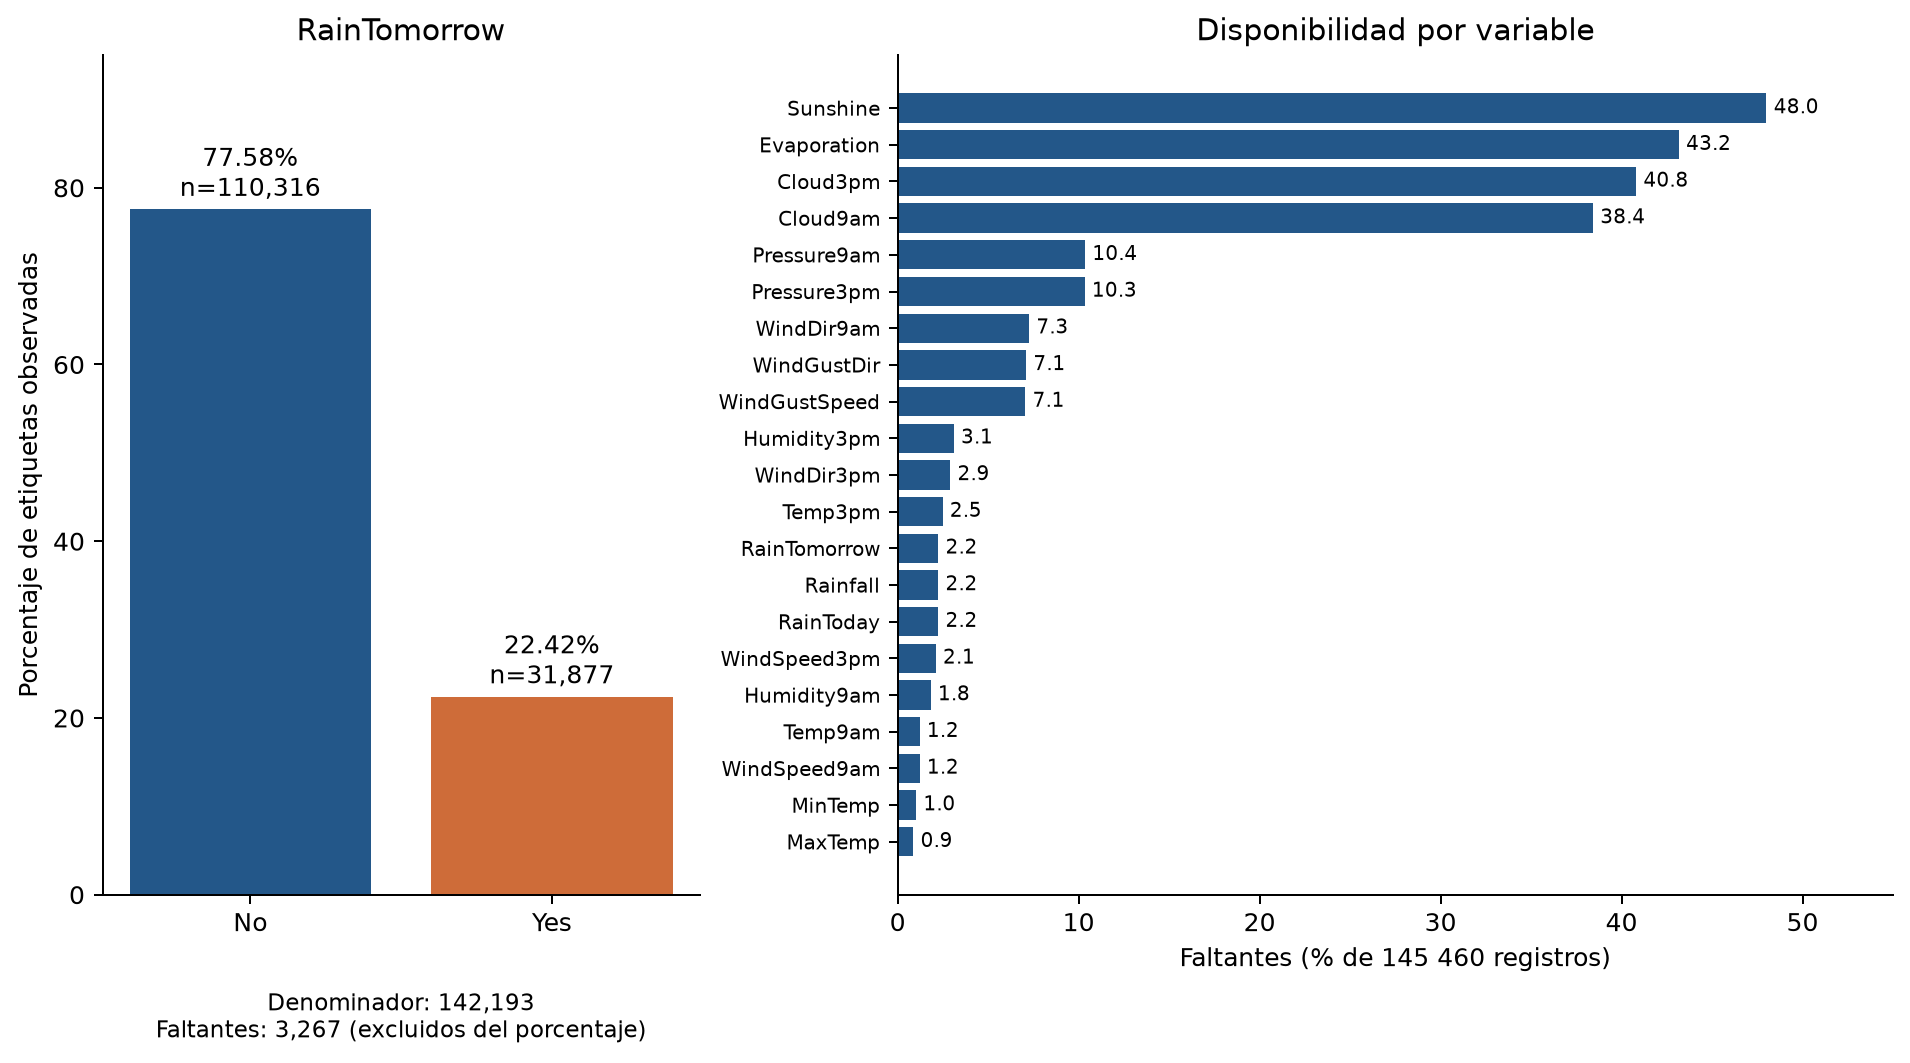

In [14]:
mostrar_figura("01_objetivo_faltantes.png")


### Distribuciones meteorológicas

Las líneas identifican media y mediana de los registros. Rainfall utiliza log(1+x)
solo para el eje del gráfico, con etiquetas en milímetros; no se transforma el dataset.
La cola de lluvia muestra episodios poco frecuentes que el promedio por sí solo oculta.


In [ ]:
mostrar_figura("02_distribuciones.png")


### Relaciones con el objetivo

Los boxplots resumen mediana e IQR. Se ocultan los puntos exteriores únicamente
en el dibujo para facilitar lectura: todos los valores intervienen en el cálculo.
El solapamiento de las distribuciones impide convertir una diferencia de medias
en una regla de predicción perfecta.


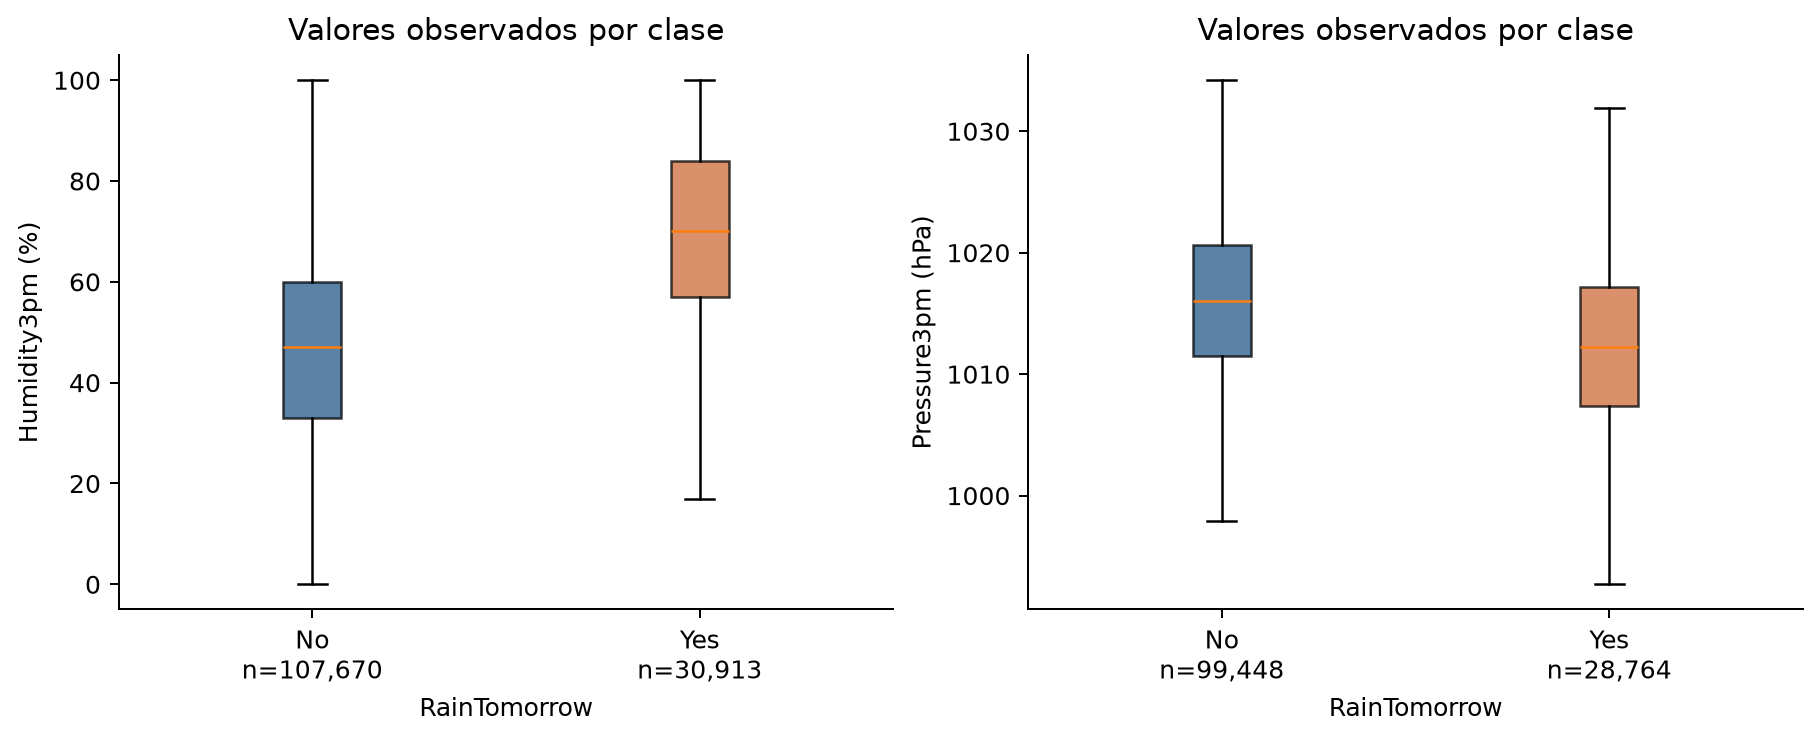

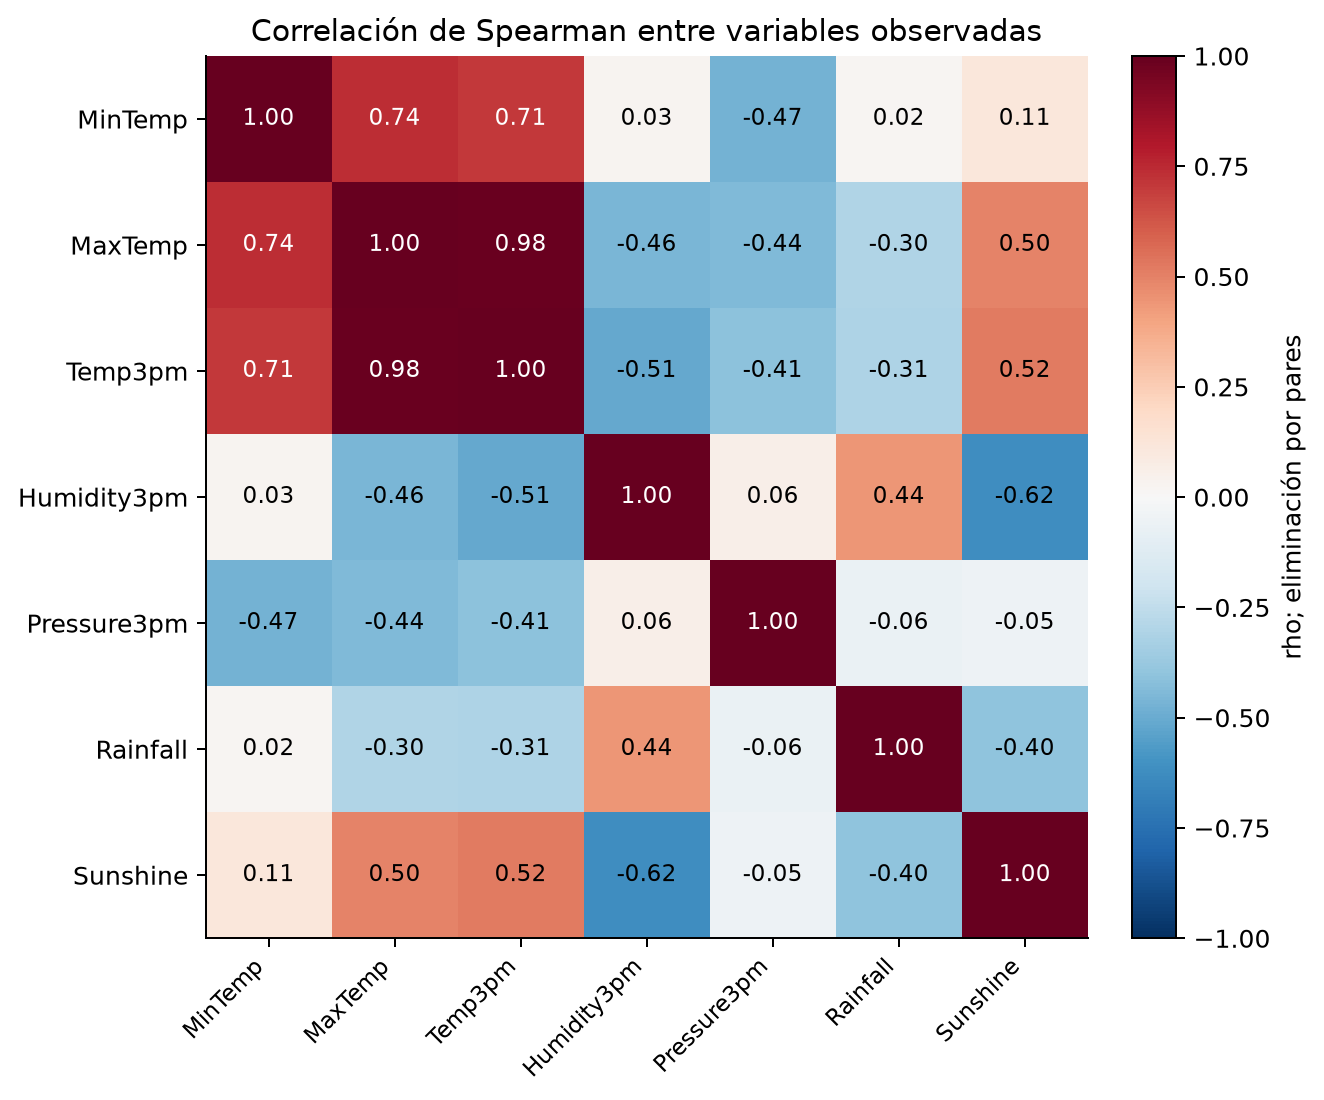

In [15]:
mostrar_figura("03_relaciones_objetivo.png")
mostrar_figura("04_correlaciones.png", 750)


### Variación geográfica y estacional

Darwin, Perth, Sydney y Hobart ilustran cuatro localidades de referencia. Las curvas
son frecuencias observadas por mes del registro, con denominadores distintos.
El panel de extremos muestra ocho de las 49 localidades; las tablas conservan todas.
No se interpreta la curva conjunta como una climatología nacional equilibrada.


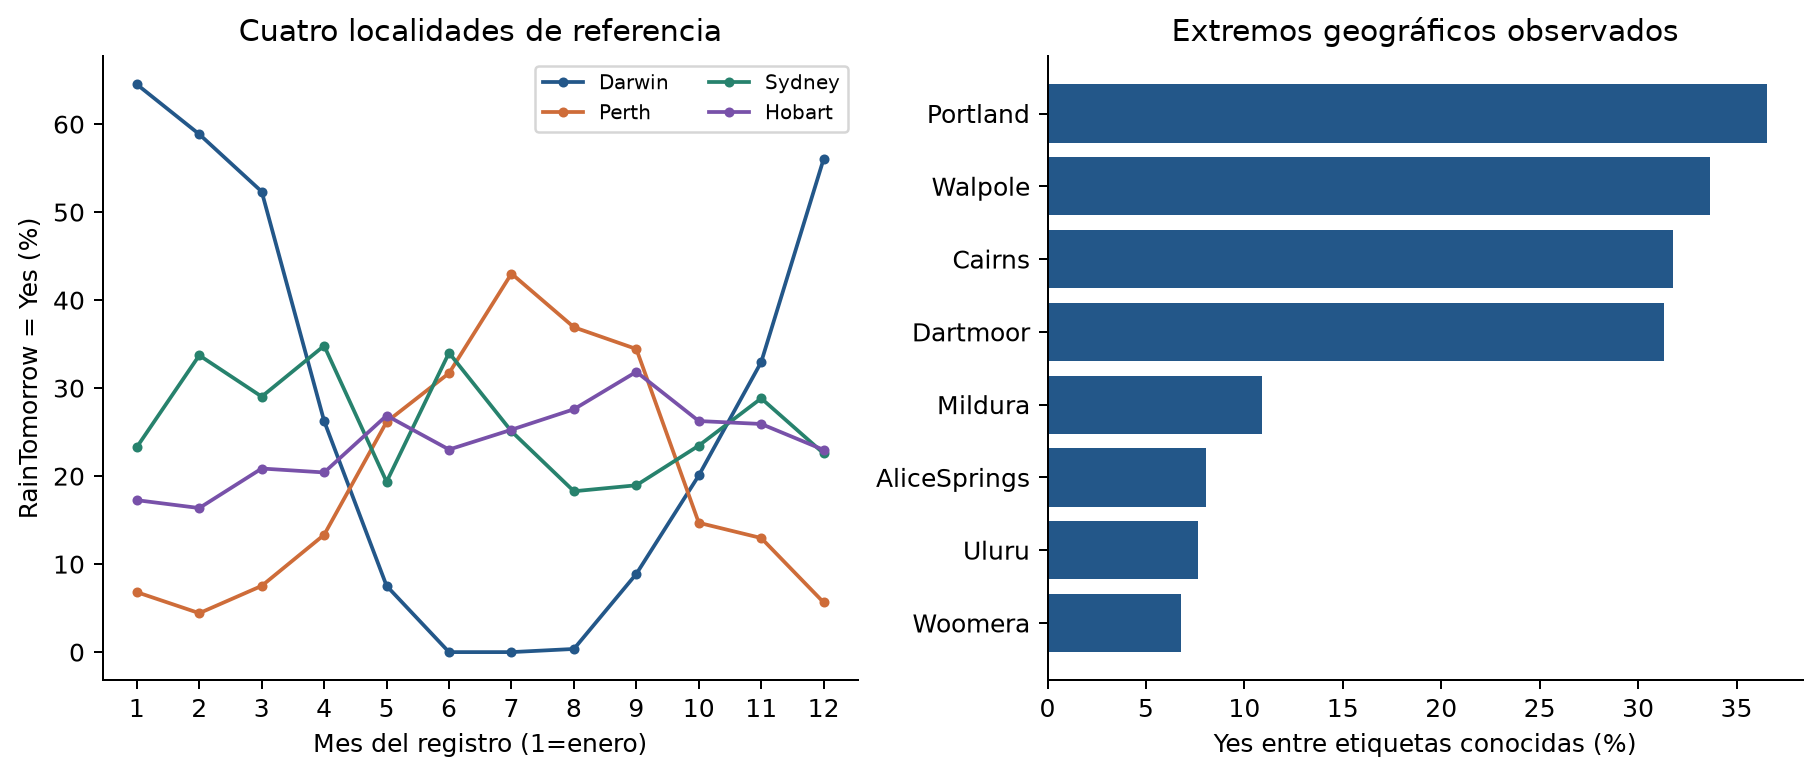

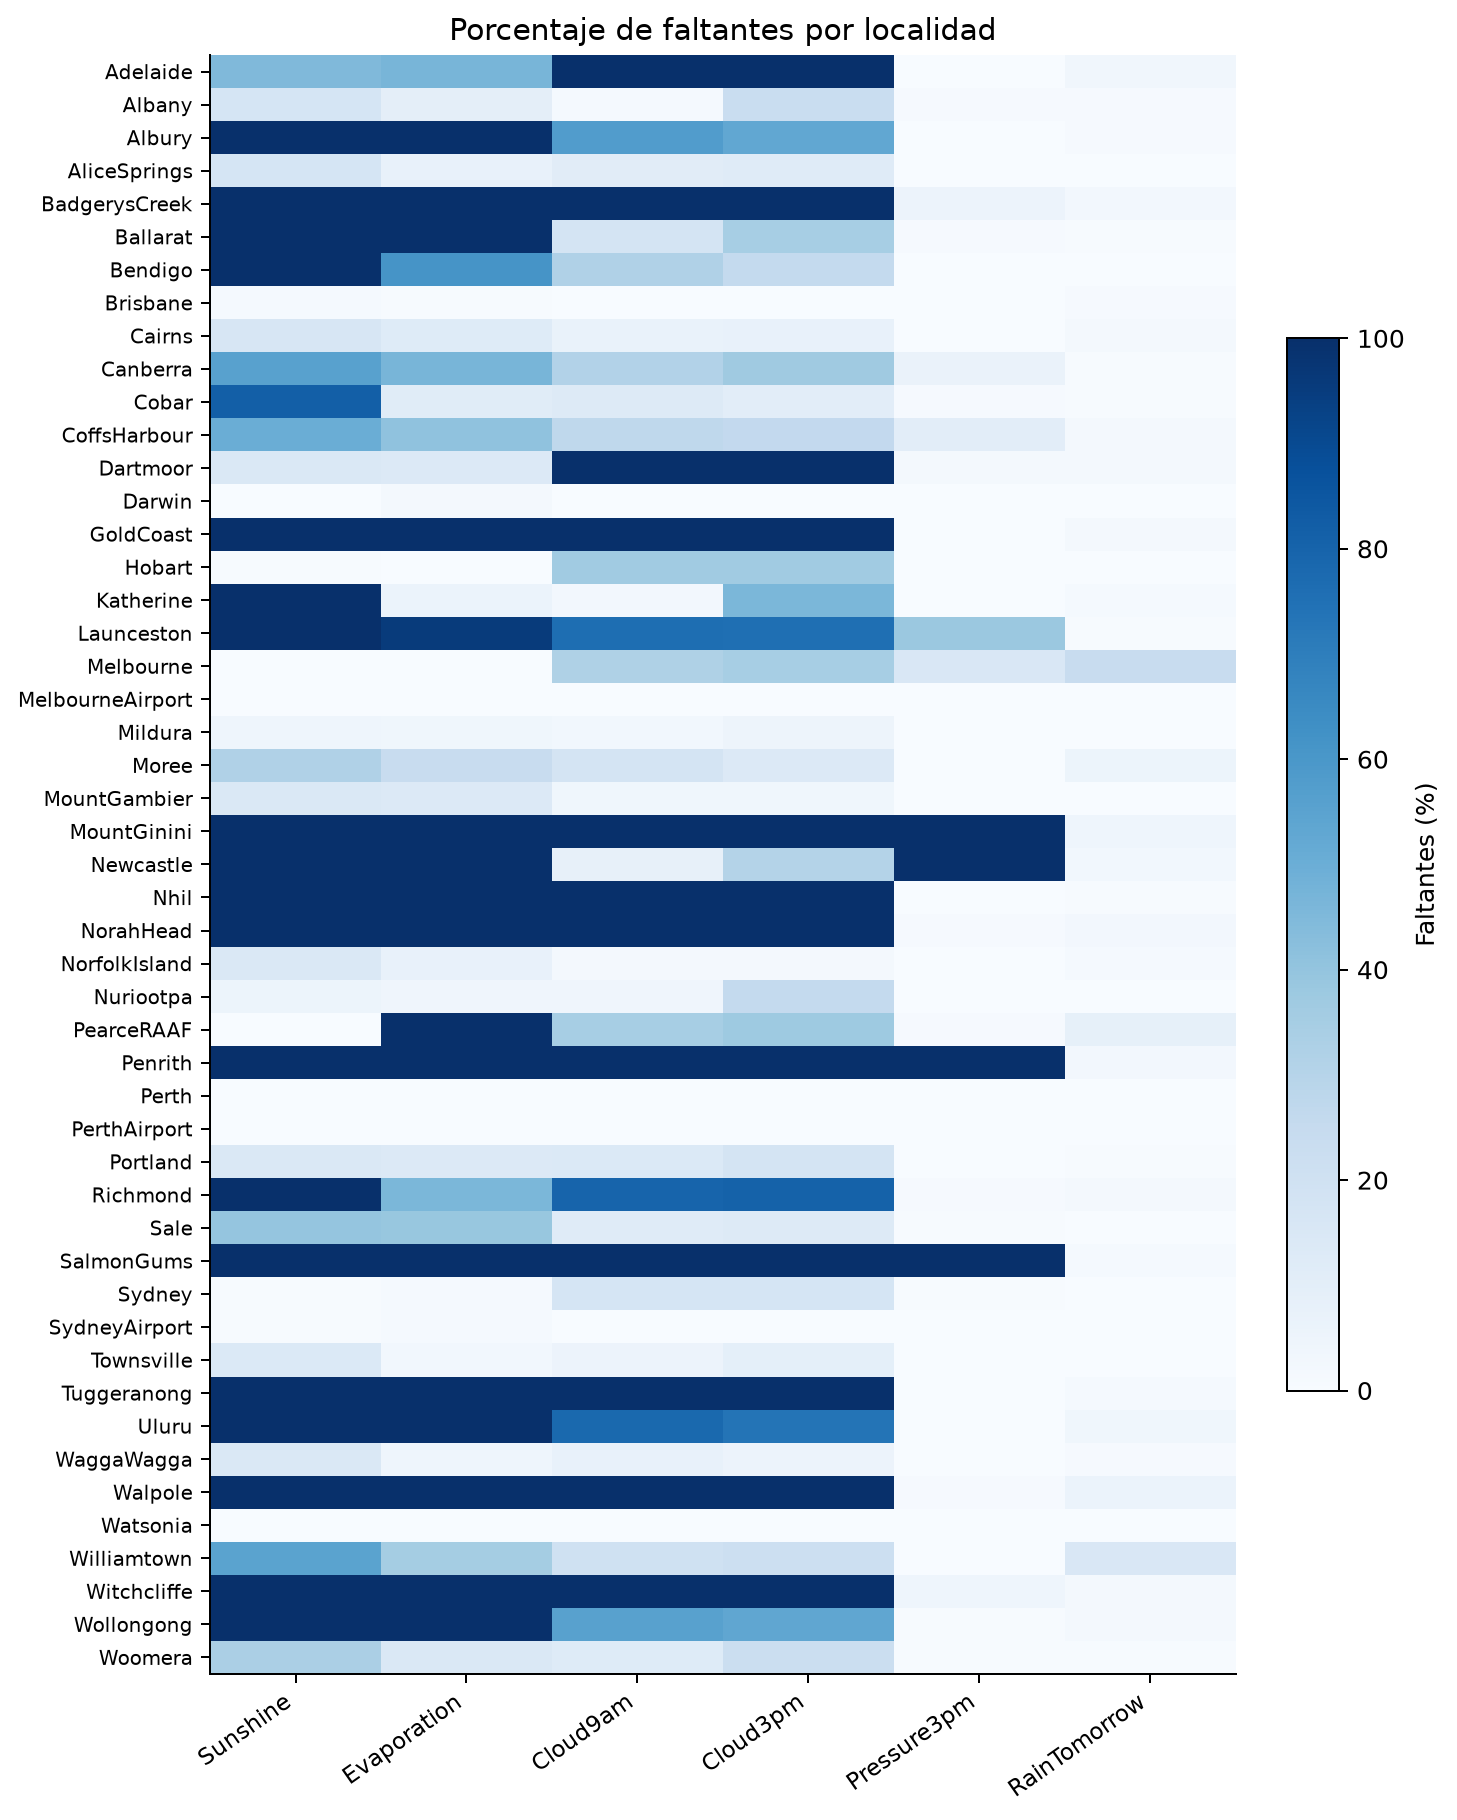

In [16]:
mostrar_figura("05_geografia_estacionalidad.png")
mostrar_figura("08_faltantes_localidades.png", 800)


### Diagnóstico de los resúmenes inferenciales

En los Q-Q, grandes desvíos de la recta señalarían incompatibilidad con una distribución
normal. La aproximación gráfica y Shapiro–Wilk no demuestran independencia espacial.
Las localidades extremas en temperatura o humedad se conservan. La gráfica de
diferencias permite comprobar su heterogeneidad y dirección en cada localidad.


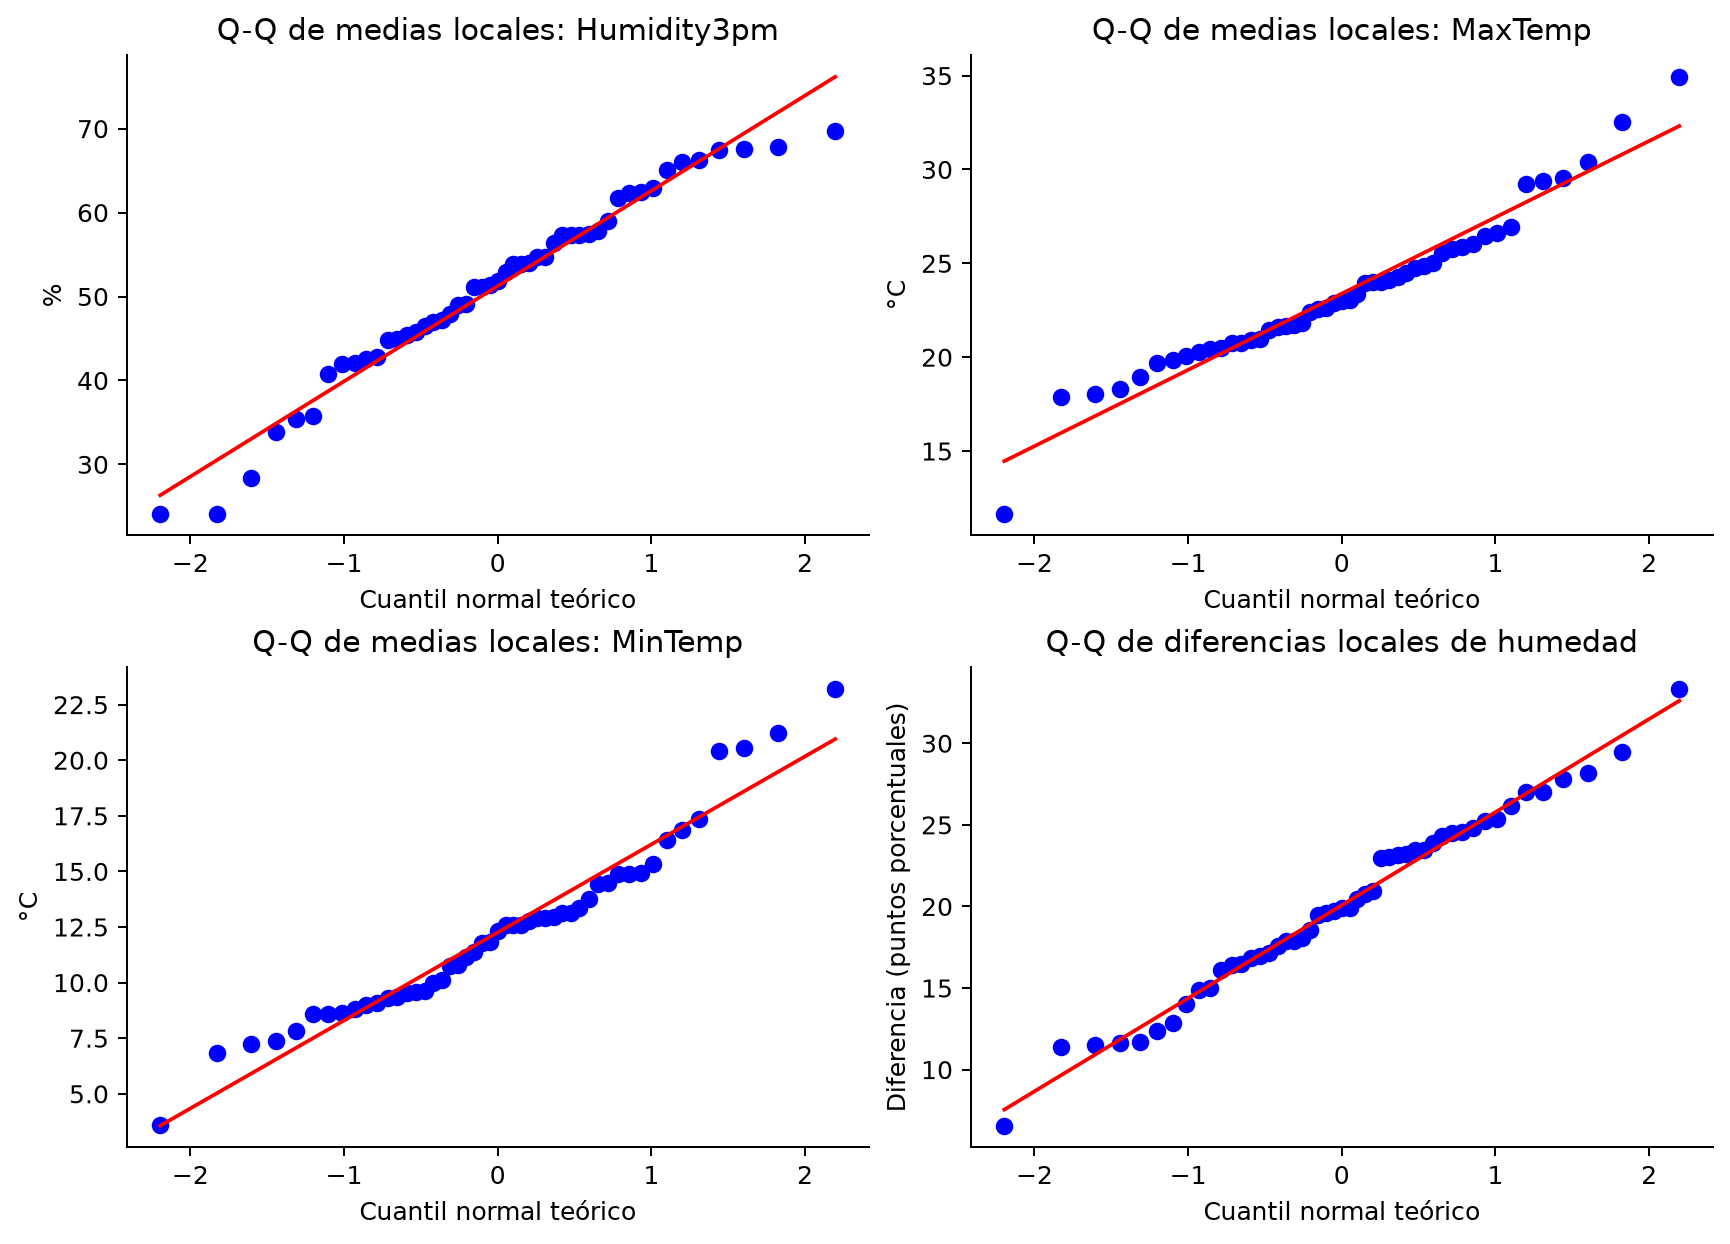

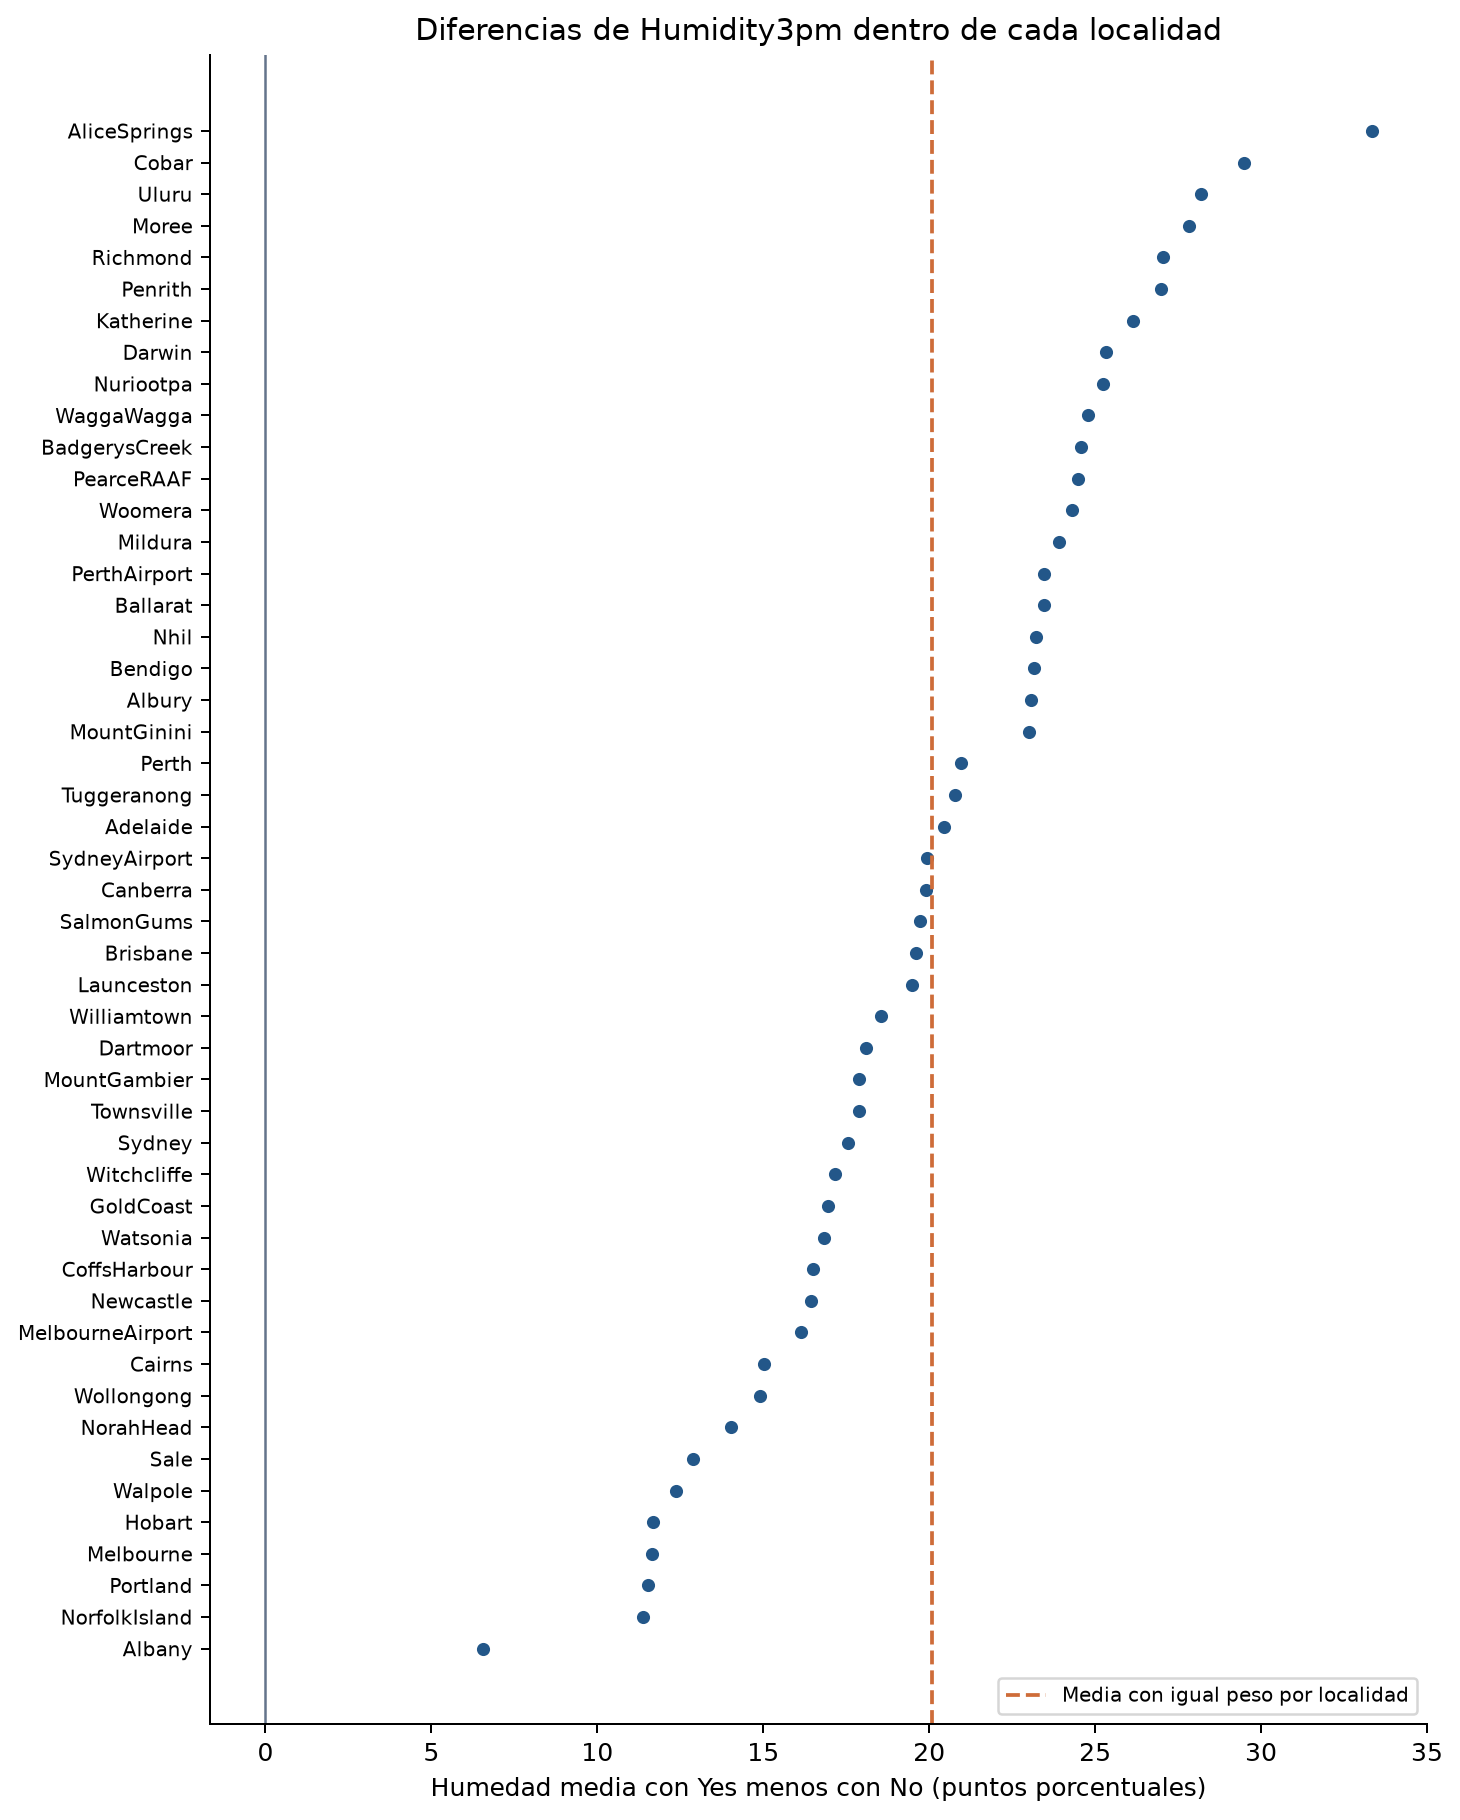

In [17]:
mostrar_figura("06_diagnostico_normalidad.png")
mostrar_figura("07_diferencias_localidades.png", 800)


## Validación y evidencia de ejecución

Conciliamos denominadores, totales por localidad, faltantes, número de variables y
registros usados por la prueba. Los intervalos calculados con la fórmula explícita
se contrastan con SciPy. Con pesos por n local recuperamos las medias agrupadas.
Por último volvemos a leer y comparar el CSV y su SHA-256 para comprobar que no cambió.

La evidencia se guarda como `ejecucion_work.json` en Work y `ejecucion_windows.json`
al ejecutar desde Windows. Se mantienen separados del registro original `entorno.json`.
**Un control numérico correcto no establece la validez de todos los supuestos estadísticos.**


In [18]:
evidencia = f1.comprobar_resultados(datos_originales, datos, tablas, resumen, RAIZ)
print("FORMATIVA 1 — EJECUCIÓN COMPLETA: CORRECTA")
print("Controles numéricos:", evidencia["controles_numericos"])
print("CSV original sin modificaciones:", evidencia["csv_original_sin_modificaciones"])
print("Entorno ejecutado:", evidencia["entorno"])
print("Evidencia:", f"evidence/01_formativa1/ejecucion_{evidencia['entorno']}.json")
print("Pendientes académicos: verificar integrantes, fecha y formato vigentes en Canvas; entregar PDF y participar en foro.")


FORMATIVA 1 — EJECUCIÓN COMPLETA: CORRECTA
Controles numéricos: correctos
CSV original sin modificaciones: True
Entorno ejecutado: windows
Evidencia: evidence/01_formativa1/ejecucion_windows.json
Pendientes académicos: verificar integrantes, fecha y formato vigentes en Canvas; entregar PDF y participar en foro.


## Interpretación contextual y limitaciones

La humedad de la tarde muestra una asociación consistente con lluvia al día siguiente
en las localidades analizadas. La magnitud de la diferencia justifica estudiarla como
candidata en fases posteriores. La dispersión, el solapamiento y los patrones de
faltantes exigen conservar incertidumbre antes de apoyar decisiones agrícolas,
turísticas o de gestión hídrica.

Las limitaciones concretas son:

- Fechas y cobertura desiguales, dependencia entre días y posible correlación espacial.
- Selección no aleatoria de localidades, ausencia de garantía de representatividad nacional.
- Faltantes estructurados y comparación de clases con distinta mezcla de meses y años.
- Intervalos y p-valores exploratorios condicionados al modelo, sin ajuste espacial.
- Investigación de varias relaciones en el mismo archivo: la evidencia es exploratoria,
  aunque se presenta una sola comparación principal, sin pretensión confirmatoria externa.
- El archivo completo ya se exploró. En modelamiento futuro se deberá ajustar imputación,
  estandarización y selección dentro del entrenamiento y documentar que la evaluación
  retrospectiva no equivale a un conjunto externo nunca examinado.
- El origen temporal de la predicción y la disponibilidad efectiva de cada predictor
  siguen pendientes; ningún modelo ni partición definitiva se construye aquí.

No se diagnostica MCAR/MAR/MNAR solo con porcentajes. No se imputa la variable objetivo,
no se elimina globalmente por casos completos y no se interpreta correlación como causalidad.


## Conclusiones y continuidad

El dataset es viable para el proyecto acumulativo por su objetivo binario y sus
mediciones meteorológicas, con condiciones metodológicas que deben mantenerse visibles.
Se conserva el archivo original y una ficha de sus 23 variables. Los resúmenes por
localidad y los conteos efectivos permiten reutilizar los mismos estimandos sin
cambiar silenciosamente su definición entre evaluaciones.

Los parámetros de continuidad son las medias locales de Humidity3pm, MaxTemp y
MinTemp y la diferencia local de Humidity3pm entre Yes y No. Su validación mediante
remuestreo, simulación o modelamiento se realizará cuando se autorice esa evaluación.
Los archivos y limitaciones quedan registrados en `docs/continuidad.md`.

Antes de entregar, se debe revisar el PDF con el grupo, reproducir este notebook
en Windows y completar publicación y comentarios reales en Canvas. El paquete
incluye un borrador de publicación y una guía de retroalimentación; no constituyen
evidencia de participación efectuada.


## Referencias

Universidad Andrés Bello. (2026). *Rúbricas MCDI501* [Archivo Excel, hoja Formativa 1,
celda B3 y filas 42–70]. Material proporcionado por el estudiante.

Maidana, J. P. (2026). *MCDI501-202682* [Repositorio docente].
https://github.com/jpmaidana/MCDI501-202682

jsphyg. (s. f.). *Rain in Australia* [Conjunto de datos]. Kaggle.
https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package/data

Williams, G. (s. f.). *weatherAUS: Daily weather observations from multiple Australian
weather stations* [Documentación de Rattle].
https://search.r-project.org/CRAN/refmans/rattle/html/weatherAUS.html

Bureau of Meteorology. (2010, 9 de agosto). *Definitions for 9am and 3pm statistics*.
https://www.bom.gov.au/climate/cdo/about/definitions9and3.shtml

Bureau of Meteorology. (2024, 17 de junio). *State-based half hourly observations
(72-hour history): User guide* (versión 3.2, apéndice 2).
https://www.bom.gov.au/catalogue/72_hr_historical_obs.pdf

The SciPy community. (s. f.). *scipy.stats.ttest_1samp*.
https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_1samp.html

The SciPy community. (s. f.). *scipy.stats.shapiro*.
https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html

Las fuentes web se consultaron el 10 de octubre de 2026. Las cifras proceden de la
copia CSV identificada por SHA-256, no de los ejemplos docentes ni de versiones
actualizadas de Rattle. Las referencias APA se incluyen como buena práctica;
no se declara un requisito APA específico no confirmado para F1.
